# Tutorial 10. From a model to a digital twin: fit, forecast, audit, decide

![From a model to a digital twin](../tutorials/images/t10_hero.png)

**Scope:** the twin workflow, on the elevated tank of Tutorial 5. **Components:**
`Tank`, `FlowSource`, `Atmosphere`, and your own: a `Component` subclass (a
valve) and a `Composite` (the tank with its valve).

## The asset, and the question Otwin exists for

The elevated tank of the water supply has a level transmitter. Water comes in
from the pump station and leaves through a service valve to the town. The valve
coefficient is not on any data sheet, and it changes as the valve wears. The
utility wants a forecast of the level six hours ahead, with a range it can trust,
and a system that refuses to answer when it has no basis to.

![Data flow](../tutorials/images/t10_pd.png)

The steps: build the model (with a component the library does not have), fit
the unknown coefficient to measurements, calibrate a forecast range on
out-of-sample errors, audit the range by horizon on days the model never saw,
and let the validity envelope decide what may be answered.

## Step 1. Write a component

The library has an `Orifice`, but a service valve has an *opening*. A component
is a class with ports, parameters and one or more branches; the compiler reads
the branches and nothing else. Here is a valve: a resistor branch whose law is
Q = C_v · opening · √(Δp).

In [ ]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin import expr as ex
from otwin.components.base import Component, Composite, ResistorBranch
from otwin.components.hydraulic import Atmosphere, FlowSource, Tank

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])
warnings.filterwarnings("ignore", category=UserWarning)
AREA = 150.0  # m2, the elevated tank


class Valve(Component):
    """A service valve: Q = C_v * opening * sqrt(dp), both directions."""

    domain = "hydraulic"
    type_name = "valve"

    def __init__(self, c_v=1e-5, *, opening=1.0, name=None):
        super().__init__(name)
        self.add_port("a")
        self.add_port("b")
        self.cv = self.add_parameter(
            "c_v", c_v, "m^3/(s Pa^0.5)", "flow coefficient at full opening"
        )
        self.opening = self.add_parameter(
            "opening", opening, "1", "0 closed to 1 open", positive=False, nonneg=True
        )

    def branches(self):
        law = lambda dp: ex.sign(dp) * self.cv * self.opening * ex.sqrt(abs(dp))  # noqa: E731
        return [ResistorBranch(self, self.a, self.b, law=law)]


class ServiceTower(Composite):
    """An elevated tank with its service valve, as one part with ports ``inlet``
    (the tank) and ``outlet`` (after the valve)."""

    type_name = "service_tower"
    domain = "hydraulic"

    def __init__(self, c_v, *, level=2.0, name=None):
        super().__init__(name)
        tank = Tank(AREA, level=level, base_elevation=30.0, name="tank")
        valve = Valve(c_v, name="valve")
        self.add(tank, valve)
        self.connect(tank.port, valve.a)
        self.expose("inlet", tank.port)
        self.expose("outlet", valve.b)


def tower_model(c_v):
    tower = ServiceTower(c_v, name="tower")
    inflow = FlowSource(None, name="inflow")  # m3/s from the pump station, an input
    atm = Atmosphere(name="atm")
    s = otwin.System(tower, inflow, atm)
    s.connect(inflow.a, tower.inlet)
    s.connect(tower.outlet, inflow.b, atm.port)
    return otwin.compile(s)


model = tower_model(c_v=0.9e-4)
print(model.summary())

System: system

Components:
  tower.tank                   tank [hydraulic]
  tower.valve                  valve [hydraulic]
  inflow                       flow_source [hydraulic]
  atm                          atmosphere [any]

States:
  tower.tank.volume            volume [m^3]  x0 = 300

Inputs:
  inflow                       flow [m^3/s]

Parameters:
  tower.tank.area              150          m^2
  tower.tank.base_elevation    30           m
  tower.tank.density           1000         kg/m^3
  tower.tank.gravity           9.81         m/s^2
  tower.valve.c_v              9e-05        m^3/(s Pa^0.5)
  tower.valve.opening          1            1

Outputs: 13 named quantities (model.outputs())
Representation: port-hamiltonian
Backend: rust


One state, the tank volume; one input, the inflow. The composite's parts appear
as `tower.tank.volume` and `tower.valve.c_v`: a `Composite` renames its
parts, so your device looks like any library device. Nothing in the valve class
is a differential equation; the compiler wrote the balance at the tower node.

## Step 2. Measurements

There is no real tank here, so we make one: the same model with the true valve
coefficient (worn, 20 % above the nominal), a pump schedule the operator knows,
and a level sensor with 1 cm of noise, over 14 days at 10 minute intervals. The
tank's time constant is hours, so the explicit `rk4` at a 10 minute step is
accurate and fast; it is used throughout.

In [ ]:
DT = 600.0
t = np.arange(0, 14 * 86400, DT)
rng = np.random.default_rng(7)


def pump_schedule(time):
    h = (time / 3600) % 24
    return (
        0.070 if (h < 7 or 12 <= h < 15 or h >= 22) else 0.050
    )  # m3/s: more at night and midday


truth = tower_model(c_v=1.08e-4)
real = truth.simulate(
    t=t,
    inputs={"inflow": pump_schedule},
    x0={"tower.tank.volume": AREA * 2.0},
    solver="rk4",
)
level_true = real["tower.tank.level"]
measured = level_true + rng.normal(0, 0.01, t.size)
inflow = np.array([pump_schedule(x) for x in t])
print(
    f"14 days of level readings: {measured.min():.2f} to {measured.max():.2f} m, "
    f"outflow through the valve {real['tower.valve.flow'].mean() * 1e3:.0f} L/s on average"
)

14 days of level readings: 0.33 to 3.46 m, outflow through the valve 60 L/s on average


## Step 3. Fit the valve

`fit_parameters` moves the named parameters until the model's outputs match the
measurements, and reports whether the data determined each one. Fit on the
first three days.

In [ ]:
from otwin.hybrid import fit_parameters

fit_days = t < 3 * 86400
fit = fit_parameters(
    model,
    t[fit_days],
    {"tower.tank.level": measured[fit_days]},
    ["tower.valve.c_v"],
    inputs={"inflow": inflow[fit_days]},
    x0={"tower.tank.volume": AREA * measured[0]},
    solver="rk4",
)
print(fit)
print(
    f"fitted C_v {fit.values['tower.valve.c_v']:.3e}, true {1.08e-4:.3e}, nominal was {0.9e-4:.3e}; "
    f"identified: {fit.identifiability.verdicts}"
)
twin = fit.model

FitResult(tower.valve.c_v=0.000108002; cost=0.01876, evaluations=10, identified={'tower.valve.c_v': True})
fitted C_v 1.080e-04, true 1.080e-04, nominal was 9.000e-05; identified: {'tower.valve.c_v': True}


The fitted coefficient lands on the true one to within the noise, and the
identifiability check says the data determined it: the inflow changes four
times a day, so the level responds to the valve in a way the fit can see. A flat
inflow would have left C_v confounded with the pump flow, and the verdict would
have said so.

## Step 4. Forecast with a calibrated range

A forecast six hours ahead starts from the last reading and runs the fitted model
forward with the known pump schedule. How wrong is it? Collect genuine six-hour
errors from rolling origins inside the first ten days, then calibrate a 90 %
band that widens with the horizon.

In [ ]:
from otwin.forecast import horizon_conformal, rolling_origin_residuals

H = 36  # 36 steps of 10 min = 6 h


def forecaster(history, horizon):
    k = len(history)
    out = twin.simulate(
        t=t[k - 1 : k + horizon],
        x0={"tower.tank.volume": AREA * float(history[-1])},
        inputs={"inflow": inflow[k - 1 : k + horizon]},
        solver="rk4",
    )
    return out["tower.tank.level"][1:]


calibration_days = t < 10 * 86400
res, hor = rolling_origin_residuals(
    forecaster, measured[calibration_days], step=12, min_train=144, max_horizon=H
)
band = horizon_conformal(res, hor, level=0.9, max_horizon=H)
print(
    f"{res.size} out-of-sample errors; 90 % half-width {band.half_width[0] * 100:.1f} cm at 10 min, "
    f"{band.half_width[-1] * 100:.1f} cm at 6 h"
)

3852 out-of-sample errors; 90 % half-width 2.4 cm at 10 min, 2.3 cm at 6 h


The band is a few centimetres: the model is good, and the band grows with the
horizon as errors accumulate. These are *forecast* errors, not fitting
residuals; calibrating on fitting residuals gives a band about ten times too
narrow, which is the mistake Otwin's interface is built to prevent.

## Step 5. Audit the range on days the model never saw

Days 10 to 14 were used for nothing so far. Forecast from every hour, compare
with what happened, and ask: did the 90 % range hold 90 %, overall and by
horizon?

In [ ]:
from otwin.audit import coverage_audit

obs, pred, lo, up, hh = [], [], [], [], []
for k in range(int(10 * 86400 / DT), t.size - H, 6):
    p = forecaster(measured[:k], H)
    low, high = band.apply(p)
    obs.append(measured[k : k + H])
    pred.append(p)
    lo.append(low)
    up.append(high)
    hh.append(np.arange(1, H + 1))
cat = np.concatenate
audit = coverage_audit(
    cat(obs),
    cat(pred),
    cat(lo),
    cat(up),
    level=0.9,
    horizons=cat(hh),
    tranches=[0, 6, 18, 36],
)
rows = [audit.overall, *audit.tranches]
print(
    pd.DataFrame(
        [
            {
                "horizon (steps)": r.label,
                "contrasts": r.n_contrasts,
                "coverage": r.coverage,
                "95% interval": f"{r.ci_low:.3f} to {r.ci_high:.3f}",
                "bias (cm)": r.median_error * 100,
                "width (cm)": r.mean_width * 100,
                "verdict": r.verdict,
            }
            for r in rows
        ]
    )
    .round(3)
    .to_string(index=False)
)

horizon (steps)  contrasts  coverage   95% interval  bias (cm)  width (cm)                verdict
            all       3240     0.915 0.905 to 0.925     -0.152       4.687      wider than stated
         (0, 6]        540     0.917 0.890 to 0.939     -0.155       4.754 consistent with stated
        (6, 18]       1080     0.902 0.883 to 0.919     -0.143       4.695 consistent with stated
       (18, 36]       1620     0.924 0.910 to 0.937     -0.152       4.660      wider than stated


The verdict per tranche says whether the delivered coverage is consistent with
the stated 90 %, with a confidence interval that accounts for how many contrasts
each tranche has. A range that covers more than it states is reported as wider
than it needs to be, not as a success. Here every tranche is consistent with the
stated level. When the overall number is on target but a tranche is not, this
view is what shows it: a band that widens with the horizon by a fitted power law
can give the short horizons less than they need and the long ones more. The
bias column is the median signed error: a systematic offset shows here before
it shows in coverage.

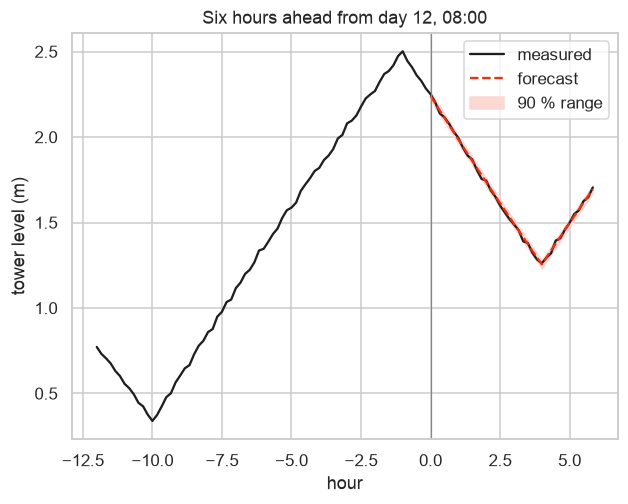

In [ ]:
k = int(12 * 86400 / DT) + 48  # day 12, 08:00
p = forecaster(measured[:k], H)
low, high = band.apply(p)
frame = pd.DataFrame(
    {"hour": (t[k - 72 : k + H] - t[k]) / 3600, "measured": measured[k - 72 : k + H]}
)
fc = pd.DataFrame(
    {"hour": (t[k : k + H] - t[k]) / 3600, "forecast": p, "low": low, "high": high}
)
ax = sns.lineplot(data=frame, x="hour", y="measured", color="#201E1D", label="measured")
sns.lineplot(
    data=fc, x="hour", y="forecast", color="#EC3013", ls="--", label="forecast", ax=ax
)
ax.fill_between(fc["hour"], fc["low"], fc["high"], color="#FBD9D2", label="90 % range")
ax.axvline(0, color="#8A8886", lw=0.8)
ax.set_ylabel("tower level (m)")
ax.set_title("Six hours ahead from day 12, 08:00")
ax.legend()

## Step 6. Record it, and let the twin say no

The manifest records what was fitted, how it was validated and what coverage was
measured. The envelope reads the manifest and refuses questions outside it: a
twelve-hour forecast when six were validated, or a level outside the range the
fit saw.

In [ ]:
from otwin.advise import Envelope
from otwin.interfaces import Provenance, TwinManifest

manifest = TwinManifest(
    name="tower-TK-102",
    model_class="compiled",
    model_kind="tank_and_valve",
    n_states=1,
    n_inputs=1,
    parameters=fit.values,
    estimated=("tower.valve.c_v",),
    validation=TwinManifest.validated_by(
        "rolling_origin", horizon=H, n_residuals=int(res.size)
    ),
    calibration=TwinManifest.calibrated_by(
        "horizon_conformal", empirical_coverage=audit.overall.coverage, level=0.9
    ),
    identification=TwinManifest.identified_by(
        "sensitivity", parameters=fit.identifiability.verdicts
    ),
    provenance=Provenance.now(
        otwin.__version__, script="tutorials/src/10_from_model_to_twin.py", seed=7
    ),
)
envelope = Envelope(
    state_bounds=[
        (AREA * measured.min(), AREA * measured.max())
    ],  # per state, in state order
    max_horizon=H,
    requires_validated=True,
    requires_calibrated=True,
    requires_identified=True,
)
for horizon, level in ((H, 1.5), (2 * H, 1.5), (H, 7.0)):
    verdict = envelope.check(
        state=np.array([AREA * level]),
        horizon=horizon,
        manifest=manifest,
        wants_interval=True,
    )
    print(
        f"ask {horizon * 10 / 60:.0f} h ahead at level {level} m -> {'answer' if verdict else 'refuse'}: "
        f"{verdict.explain().splitlines()[0] if verdict else verdict.breaches[0]}"
    )

ask 6 h ahead at level 1.5 m -> answer: inside the validated envelope (horizon 36 <= 36; operating point inside the identified range; validated, leakage-free; estimated parameters identified; coverage measured at 0.92)
ask 12 h ahead at level 1.5 m -> refuse: horizon: beyond the validated forecast horizon (asked for 72, validated to 36)
ask 6 h ahead at level 7.0 m -> refuse: state: state 0 above the identified range (asked for 1050, validated to 519.397)


The first question is inside everything that was shown to work and gets an
answer. The second asks twice the validated horizon and is refused, naming the
horizon. The third asks about a level the fit never saw and is refused for that.
A refusal is not a failure: the twin has not been shown to answer, and a number
would hide that.

## What to take from this

- Writing a component is a class with ports, parameters and a branch; a
  `Composite` packages parts into a device.
- `fit_parameters` fits named parameters and says whether the data determined
  them.
- A forecast range is calibrated on genuine out-of-sample errors and audited on
  days the model never saw, by horizon.
- The manifest records the claims and the envelope enforces them.

This is the end of the series. The [component reference](../docs/reference/components.md)
lists every component with its ports, parameters and outputs.